# 05 Warm start the paper's inverse simulation with the predictor

For test spheres the paper's 1D x search (`run_inverse_1d` in 00_common, same algorithm and hyper parameters as the authors' OptimizePar notebook) runs twice:

* **cold start:** x starts at 0, as in the paper notebook,
* **warm start:** x starts at the predictor's estimate.

We record the final error, the iterations needed to get within 1 mm, and the wall time. y, z and radius are given the true values in both cases, exactly like the paper's 1D experiment, so the comparison is fair.

In [1]:
%run ./00_common.ipynb

C:\Users\Rey\anaconda3\envs\kolb\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


PROJECT  : C:\Users\Rey\Documents\Kolb_Radar_Project
FAKE_MODE: False
[mitsuba] Warning: Couldn't import the ipywidgets package. Installing this package is required for the system to properly log messages and print in Jupyter notebooks!


torch device: cuda
mitsuba variant: cuda_ad_rgb


Switched off Tx:  2
Switched off Rx:  10
torch 2.5.1+cu121 | device cuda
common ready


In [2]:
N_CASES = int(os.environ.get('KOLB_WARM_CASES', '10')); EPOCHS = int(os.environ.get('KOLB_WARM_EPOCHS', '50'))
X, P = load_dataset(); _, _, te = split_indices(len(X))
cases = te[:N_CASES]
model = OneShotNet().to(DEVICE); model.load_state_dict(torch.load(MODELS / 'oneshot_fp32.pt', map_location=DEVICE)); model.eval()
rows = []
for k, i in enumerate(cases):
    gt = P[i]
    t0 = time.time()
    with torch.no_grad():
        pu = model(torch.from_numpy(X[i:i+1].astype(np.float32)).to(DEVICE)).cpu().numpy()
    x_pred = float(from_unit(pu)[0, 0]); t_pred = time.time() - t0
    cold = run_inverse_1d(gt, 0.0, epochs=EPOCHS)
    warm = run_inverse_1d(gt, x_pred, epochs=EPOCHS)
    row = {'case': int(i), 'true_x_mm': float(gt[0]) * 1000, 'pred_x_mm': x_pred * 1000, 'pred_seconds': t_pred,
           'cold': {kk: cold[kk] for kk in ('final_err_mm', 'iters_to_tol', 'seconds')},
           'warm': {kk: warm[kk] for kk in ('final_err_mm', 'iters_to_tol', 'seconds')},
           'cold_hist': cold['history_mm'], 'warm_hist': warm['history_mm']}
    rows.append(row)
    print(f"case {k+1}/{len(cases)}: true {row['true_x_mm']:.1f} mm, predicted {row['pred_x_mm']:.1f} mm | "
          f"cold err {cold['final_err_mm']:.2f} mm iters {cold['iters_to_tol']} | warm err {warm['final_err_mm']:.2f} mm iters {warm['iters_to_tol']}")
    save_json(rows, '05_warm_start_cases.json')   # save after every case, so nothing is lost

case 1/6: true 39.8 mm, predicted 39.5 mm | cold err 0.81 mm iters 2 | warm err 0.20 mm iters 23
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05_warm_start_cases.json


case 2/6: true -34.1 mm, predicted -32.1 mm | cold err 0.63 mm iters 6 | warm err 0.08 mm iters 7
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05_warm_start_cases.json


case 3/6: true 107.3 mm, predicted 108.2 mm | cold err 0.95 mm iters 28 | warm err 0.75 mm iters 30
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05_warm_start_cases.json


case 4/6: true 25.6 mm, predicted 25.3 mm | cold err 1.05 mm iters None | warm err 0.55 mm iters 7
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05_warm_start_cases.json


case 5/6: true -4.3 mm, predicted -5.4 mm | cold err 0.70 mm iters 12 | warm err 0.12 mm iters 6
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05_warm_start_cases.json


case 6/6: true -89.3 mm, predicted -91.0 mm | cold err 0.21 mm iters 14 | warm err 0.28 mm iters 6
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05_warm_start_cases.json


saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\05_warm_start_summary.json
{
  "cold": {
    "mean_final_err_mm": 0.7248788994426528,
    "median_final_err_mm": 0.7548913126811385,
    "reached_1mm": "5/6",
    "median_iters_to_1mm": 12.0,
    "reached_2mm": "6/6",
    "median_iters_to_2mm": 6.0,
    "median_err_mm_after_0_iters": 36.93844377994537,
    "median_err_mm_after_5_iters": 11.915287468582392,
    "median_err_mm_after_10_iters": 10.70824358612299,
    "median_err_mm_after_20_iters": 4.544716328382492,
    "mean_seconds": 340.7378040949504
  },
  "warm": {
    "mean_final_err_mm": 0.3308215333769719,
    "median_final_err_mm": 0.24062395095825195,
    "reached_1mm": "6/6",
    "median_iters_to_1mm": 7.0,
    "reached_2mm": "6/6",
    "median_iters_to_2mm": 0.0,
    "median_err_mm_after_0_iters": 0.985240563750267,
    "median_err_mm_after_5_iters": 9.222764521837234,
    "median_err_mm_after_10_iters": 9.081167168915272,
    "median_err_mm_after_20_iters": 4.24

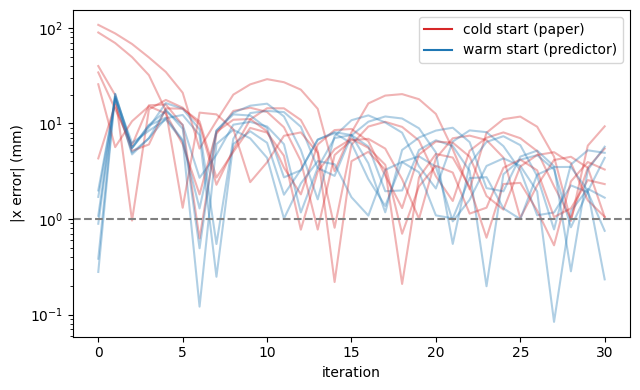

In [3]:
def summary(key):
    errs = [r[key]['final_err_mm'] for r in rows]
    its = [r[key]['iters_to_tol'] for r in rows]
    ok = [x for x in its if x is not None]
    hist = np.array([r[key + '_hist'] for r in rows])          # error in mm after each iteration (index 0 = start)
    at = {f'median_err_mm_after_{k}_iters': float(np.median(hist[:, k])) for k in (0, 5, 10, 20) if k < hist.shape[1]}
    best_so_far = np.minimum.accumulate(hist, axis=1)
    within2 = [int(np.argmax(b < 2.0)) if (b < 2.0).any() else None for b in best_so_far]
    ok2 = [x for x in within2 if x is not None]
    return {'mean_final_err_mm': float(np.mean(errs)), 'median_final_err_mm': float(np.median(errs)),
            'reached_1mm': f'{len(ok)}/{len(its)}', 'median_iters_to_1mm': float(np.median(ok)) if ok else None,
            'reached_2mm': f'{len(ok2)}/{len(within2)}', 'median_iters_to_2mm': float(np.median(ok2)) if ok2 else None,
            **at, 'mean_seconds': float(np.mean([r[key]['seconds'] for r in rows]))}
summ = {'cold': summary('cold'), 'warm': summary('warm'), 'n_cases': len(rows), 'epochs': EPOCHS}
save_json(summ, '05_warm_start_summary.json'); print(json.dumps(summ, indent=2))
log(f"05 warm vs cold: {json.dumps(summ)}")
import matplotlib.pyplot as plt
plt.figure(figsize=(6.5, 4))
for r in rows:
    plt.semilogy(r['cold_hist'], c='tab:red', alpha=.35); plt.semilogy(r['warm_hist'], c='tab:blue', alpha=.35)
plt.plot([], [], c='tab:red', label='cold start (paper)'); plt.plot([], [], c='tab:blue', label='warm start (predictor)')
plt.axhline(1.0, ls='--', c='grey'); plt.xlabel('iteration'); plt.ylabel('|x error| (mm)'); plt.legend()
plt.tight_layout(); plt.savefig(FIGS / '05_warm_vs_cold.png', dpi=120); plt.show()